# NB06d: K-search MIA signal

**Question:** if the total L2 budget is fixed at L2 budget at ε_target and vary the *number* of PGD steps N
(with per-step size α = ε/N), does the minimum step count N_min carry a stronger or weaker
membership inference signal than the minimum budget ε_min (NB06b)?

**Setup:**
- ε is fixed; N is searched over a geometric grid {1, 2, 4, 8, 16, 32, 64, 128}.
- α = ε / N (step size shrinks as N grows, finer gradient walk within the same ball).
- Two ε conditions:
  - **Full:** ε = ε_target (same physical budget as NB06b)
  - **Quarter:** ε = ε_target / 4 (tighter budget; tests fine-scale navigation)
- Both test (non-member) and train (member) impostor splits are attacked.
- MIA AUC(N_min) is compared to AUC(ε_min) from NB06b.

**Reads:** existing artifacts only: `06a_*_attack_setup.npz`, `auth_pairs.npz`, model checkpoints.
**Writes:** `artifacts/{dataset}/06d_{dataset}_ksearch_{cond}.npz`, `results/{dataset}/06d_*.png`,
`latex/generated/nb06d_ksearch_metrics.tex`.
**Does not modify** any previously generated artifact or LaTeX file.

In [ ]:
import sys
sys.path.insert(0, '..')

import logging
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import torch
from sklearn.metrics import roc_auc_score, roc_curve

from src.models.gait_cnn   import GaitCNN
from src.models.auth_model import AuthModel
from src.attacks.pgd       import pgd_sensor
from src.data.auth_dataset import normalize_auth
from src.utils.config_loader import dataset_dirs

# ── Dataset config ─────────────────────────────────────────────────────────────
DATASET = 'whuGAIT'   # change to run on other datasets

# Set True to skip PGD recomputation if artifacts already exist
SKIP_ATTACK_IF_EXISTS = True

DATA_ROOT    = Path('../data')

_ds_dirs     = dataset_dirs(Path('../logs'), Path('../checkpoints'),
                            artifacts_base=Path('../artifacts'),
                            results_base=Path('../results'), dataset=DATASET)
ARTIFACT_DIR = _ds_dirs['artifacts']
CKPT_DIR     = _ds_dirs['checkpoints']
RESULT_DIR   = _ds_dirs['results']
RESULT_DIR.mkdir(parents=True, exist_ok=True)

LATEX_DIR    = Path('../latex/generated')
LATEX_DIR.mkdir(parents=True, exist_ok=True)

DEVICE       = torch.device('cpu')
BATCH_SIZE   = 512

N_GRID       = [1, 2, 4, 8, 16, 32, 64, 128]
N_CAP        = 256

log = logging.getLogger('nb06d')
log.setLevel(logging.INFO)
log.handlers.clear()
log.addHandler(logging.StreamHandler())
log.info(f'NB06d — K-search MIA [{DATASET}]  SKIP_ATTACK_IF_EXISTS={SKIP_ATTACK_IF_EXISTS}')

In [2]:
# ── Load attack setup (eps_target from NB06a) ─────────────────────────────────
setup      = np.load(ARTIFACT_DIR / f'06a_{DATASET}_attack_setup.npz', allow_pickle=False)
eps_target = float(setup['eps_target'])
log.info(f'eps_target = {eps_target:.4f}')

# ── Load auth model ────────────────────────────────────────────────────────────
import json as _json
with open(CKPT_DIR / 'cnn_encoder_meta.json') as _f:
    _meta = _json.load(_f)
n_classes = _meta['n_classes']

cnn = GaitCNN(n_classes=n_classes)
cnn.load_state_dict(torch.load(CKPT_DIR / 'cnn_encoder.pt', map_location='cpu'))
auth_model = AuthModel(cnn).to(DEVICE)
auth_model.load_state_dict(torch.load(CKPT_DIR / 'auth_model.pt', map_location='cpu'))
auth_model.eval()
log.info(f'Loaded auth model  n_classes={n_classes}')

# ── Build impostor pairs (same seeds as NB06b — see src/data/attack_pairs.py) ─
# All four pair types are selected with fixed seeds so both notebooks operate on
# identical pairs.  ~3 s on CPU.
from src.data.attack_pairs import build_attack_pairs

reg = build_attack_pairs(ARTIFACT_DIR, DATA_ROOT)

X1_te, X2_te, subj_te = reg['X1_nn'], reg['X2_nn'], reg['subj1_nn']  # NN
X1_tr, X2_tr, subj_tr = reg['X1_mm'], reg['X2_mm'], reg['subj1_mm']  # MM
X1_nm, X2_nm, subj_nm = reg['X1_nm'], reg['X2_nm'], reg['subj1_nm']  # NM
X1_mn, X2_mn, subj_mn = reg['X1_mn'], reg['X2_mn'], reg['subj1_mn']  # MN

log.info(f'Pairs — NN:{len(X1_te)}  MM:{len(X1_tr)}  NM:{len(X1_nm)}  MN:{len(X1_mn)}')


eps_target = 25.4883


Loaded auth model  n_classes=98


Test  (non-member) impostor pairs: 5000


Train (member)     impostor pairs: 30000


In [3]:
# ── Core: find N_min for a set of pairs at fixed ε ────────────────────────────

def batch_psame(x1_adv_np, x2_np):
    """Return P(different) scores for all pairs."""
    scores = []
    x1t = torch.from_numpy(x1_adv_np)
    x2t = torch.from_numpy(x2_np)
    with torch.no_grad():
        for i in range(0, len(x1t), BATCH_SIZE):
            logits = auth_model(x1t[i:i+BATCH_SIZE].to(DEVICE),
                                x2t[i:i+BATCH_SIZE].to(DEVICE))
            probs  = torch.softmax(logits, dim=1)[:, 1]
            scores.append(probs.cpu().numpy())
    return np.concatenate(scores)


def find_n_min(X1, X2, eps, n_grid=N_GRID, n_cap=N_CAP, batch_size=BATCH_SIZE):
    """
    For each pair find the smallest N in n_grid such that PGD with
        K = N steps,  alpha = eps / N
    succeeds (P(different) < 0.5).  Returns n_min per pair (n_cap if resistant).
    """
    n_pairs = len(X1)
    n_min   = np.full(n_pairs, n_cap, dtype=np.int32)   # default: resistant
    solved  = np.zeros(n_pairs, dtype=bool)

    x1t = torch.from_numpy(X1)
    x2t = torch.from_numpy(X2)

    for N in n_grid:
        alpha = eps / N
        pending = np.where(~solved)[0]
        if len(pending) == 0:
            break

        # Run PGD in batches on pending pairs
        x1_adv_parts = []
        for i in range(0, len(pending), batch_size):
            idx = pending[i:i+batch_size]
            x1_adv_b = pgd_sensor(
                auth_model, x1t[idx].to(DEVICE), x2t[idx].to(DEVICE),
                target_label=0, eps=eps, alpha=alpha, K=N,
            )
            x1_adv_parts.append(x1_adv_b.cpu().numpy())
        x1_adv = np.concatenate(x1_adv_parts, axis=0)

        scores = batch_psame(x1_adv, X2[pending])
        newly  = pending[scores < 0.5]
        n_min[newly]  = N
        solved[newly] = True

        log.info(f'  N={N:3d}  alpha={alpha:.4f}  +{len(newly):4d} solved  '
                 f'total {solved.sum():4d}/{n_pairs}')

    return n_min, solved

In [4]:
# ── Run K-search: Condition A  (eps = eps_target) ─────────────────────────────
EPS_A = eps_target
_out_A      = ARTIFACT_DIR / f'06d_{DATASET}_ksearch_full.npz'
_out_A_cross = ARTIFACT_DIR / f'06d_{DATASET}_ksearch_full_cross.npz'

if SKIP_ATTACK_IF_EXISTS and _out_A.exists():
    log.info(f'Condition A: loading existing {_out_A.name}')
    _d = np.load(_out_A)
    n_min_te_A, solved_te_A = _d['n_min_te'], _d['solved_te']
    n_min_tr_A, solved_tr_A = _d['n_min_tr'], _d['solved_tr']
    subj_te = _d['subj_te']
    subj_tr = _d['subj_tr']
else:
    log.info(f'\n=== Condition A: eps = eps_target = {EPS_A:.4f} ===')
    log.info('Test split (non-members):')
    n_min_te_A, solved_te_A = find_n_min(X1_te, X2_te, EPS_A)
    log.info('Train split (members):')
    n_min_tr_A, solved_tr_A = find_n_min(X1_tr, X2_tr, EPS_A)
    np.savez(_out_A,
             eps=EPS_A,
             n_min_te=n_min_te_A, solved_te=solved_te_A, subj_te=subj_te,
             n_min_tr=n_min_tr_A, solved_tr=solved_tr_A, subj_tr=subj_tr,
             n_grid=np.array(N_GRID), n_cap=N_CAP)

if SKIP_ATTACK_IF_EXISTS and _out_A_cross.exists():
    log.info(f'Condition A cross: loading existing {_out_A_cross.name}')
    _dc = np.load(_out_A_cross)
    n_min_mn_A, solved_mn_A = _dc['n_min_mn'], _dc['solved_mn']
    n_min_nm_A, solved_nm_A = _dc['n_min_nm'], _dc['solved_nm']
    subj_mn = _dc['subj_mn']
    subj_nm = _dc['subj_nm']
else:
    log.info('MN cross-pool:')
    n_min_mn_A, solved_mn_A = find_n_min(X1_mn, X2_mn, EPS_A)
    log.info('NM cross-pool:')
    n_min_nm_A, solved_nm_A = find_n_min(X1_nm, X2_nm, EPS_A)
    np.savez(_out_A_cross,
             eps=EPS_A,
             n_min_mn=n_min_mn_A, solved_mn=solved_mn_A, subj_mn=subj_mn,
             n_min_nm=n_min_nm_A, solved_nm=solved_nm_A, subj_nm=subj_nm,
             n_grid=np.array(N_GRID), n_cap=N_CAP)

asr_te_A = solved_te_A.mean()
asr_tr_A = solved_tr_A.mean()
asr_mn_A = solved_mn_A.mean()
asr_nm_A = solved_nm_A.mean()
log.info(f'Condition A  |  NN={asr_te_A:.3f}  MM={asr_tr_A:.3f}  MN={asr_mn_A:.3f}  NM={asr_nm_A:.3f}')


Condition A: loading existing 06d_whuGAIT_ksearch_full.npz


Condition A  |  test ASR=0.998  train ASR=0.989


In [5]:
# ── Run K-search: Condition B  (eps = eps_target / 16) ──────────────────────────
EPS_B = eps_target / 16.0
_out_B      = ARTIFACT_DIR / f'06d_{DATASET}_ksearch_quarter.npz'
_out_B_cross = ARTIFACT_DIR / f'06d_{DATASET}_ksearch_quarter_cross.npz'

if SKIP_ATTACK_IF_EXISTS and _out_B.exists():
    log.info(f'Condition B: loading existing {_out_B.name}')
    _d = np.load(_out_B)
    n_min_te_B, solved_te_B = _d['n_min_te'], _d['solved_te']
    n_min_tr_B, solved_tr_B = _d['n_min_tr'], _d['solved_tr']
    subj_te = _d['subj_te']
    subj_tr = _d['subj_tr']
else:
    log.info(f'\n=== Condition B: eps = eps_target/4 = {EPS_B:.4f} ===')
    log.info('Test split (non-members):')
    n_min_te_B, solved_te_B = find_n_min(X1_te, X2_te, EPS_B)
    log.info('Train split (members):')
    n_min_tr_B, solved_tr_B = find_n_min(X1_tr, X2_tr, EPS_B)
    np.savez(_out_B,
             eps=EPS_B,
             n_min_te=n_min_te_B, solved_te=solved_te_B, subj_te=subj_te,
             n_min_tr=n_min_tr_B, solved_tr=solved_tr_B, subj_tr=subj_tr,
             n_grid=np.array(N_GRID), n_cap=N_CAP)

if SKIP_ATTACK_IF_EXISTS and _out_B_cross.exists():
    log.info(f'Condition B cross: loading existing {_out_B_cross.name}')
    _dc = np.load(_out_B_cross)
    n_min_mn_B, solved_mn_B = _dc['n_min_mn'], _dc['solved_mn']
    n_min_nm_B, solved_nm_B = _dc['n_min_nm'], _dc['solved_nm']
    subj_mn = _dc['subj_mn']
    subj_nm = _dc['subj_nm']
else:
    log.info('MN cross-pool:')
    n_min_mn_B, solved_mn_B = find_n_min(X1_mn, X2_mn, EPS_B)
    log.info('NM cross-pool:')
    n_min_nm_B, solved_nm_B = find_n_min(X1_nm, X2_nm, EPS_B)
    np.savez(_out_B_cross,
             eps=EPS_B,
             n_min_mn=n_min_mn_B, solved_mn=solved_mn_B, subj_mn=subj_mn,
             n_min_nm=n_min_nm_B, solved_nm=solved_nm_B, subj_nm=subj_nm,
             n_grid=np.array(N_GRID), n_cap=N_CAP)

asr_te_B = solved_te_B.mean()
asr_tr_B = solved_tr_B.mean()
asr_mn_B = solved_mn_B.mean()
asr_nm_B = solved_nm_B.mean()
log.info(f'Condition B  |  NN={asr_te_B:.3f}  MM={asr_tr_B:.3f}  MN={asr_mn_B:.3f}  NM={asr_nm_B:.3f}')


Condition B: loading existing 06d_whuGAIT_ksearch_quarter.npz


Condition B  |  test ASR=0.819  train ASR=0.736


In [6]:
# ── MIA signal: per-subject mean N_min ────────────────────────────────────────

def subject_mean_nmin(n_min, subj_ids):
    """Mean N_min per subject (including resistant pairs as n_cap)."""
    result = {}
    for s in np.unique(subj_ids):
        result[s] = float(n_min[subj_ids == s].mean())
    return result

def mia_auc_from_subject_scores(member_scores, nonmember_scores):
    y = np.concatenate([np.ones(len(member_scores)),
                        np.zeros(len(nonmember_scores))])
    s = np.concatenate([member_scores, nonmember_scores])
    return roc_auc_score(y, s)


for cond_label, n_min_te, n_min_tr in [
    ('A (eps_target)',    n_min_te_A, n_min_tr_A),
    ('B (eps_target/4)', n_min_te_B, n_min_tr_B),
]:
    subj_nm = subject_mean_nmin(n_min_te, subj_te)   # non-members
    subj_m  = subject_mean_nmin(n_min_tr, subj_tr)   # members

    nm_scores = np.array(list(subj_nm.values()))
    m_scores  = np.array(list(subj_m.values()))

    auc = mia_auc_from_subject_scores(m_scores, nm_scores)
    log.info(f'MIA AUC(N_min)  Cond {cond_label}:  AUC={auc:.4f}  '
             f'member_mean={m_scores.mean():.1f}  nm_mean={nm_scores.mean():.1f}')

# Reference: eps_min AUC from NB06b
d06b = np.load(ARTIFACT_DIR / f'06b_{DATASET}_attack_results.npz', allow_pickle=True)
d06b_tr = np.load(ARTIFACT_DIR / f'06b_{DATASET}_train_attack_results.npz', allow_pickle=True)

def eps_mia_auc(results_te, results_tr):
    """Per-subject mean eps_min as MIA signal."""
    def subj_eps(res, subj_key='pair_probe_subj'):
        subj_ids = res[subj_key]
        eps_min  = res['pair_eps_min']
        out = {}
        for s in np.unique(subj_ids):
            vals = eps_min[subj_ids == s]
            out[s] = float(np.nanmean(vals)) if not np.all(np.isnan(vals)) else float(eps_target * 10)
        return np.array(list(out.values()))
    nm_eps = subj_eps(results_te)
    m_eps  = subj_eps(results_tr)
    return roc_auc_score(
        np.concatenate([np.ones(len(m_eps)), np.zeros(len(nm_eps))]),
        np.concatenate([m_eps, nm_eps]),
    )

auc_eps = eps_mia_auc(d06b, d06b_tr)
log.info(f'MIA AUC(eps_min) NB06b reference:  AUC={auc_eps:.4f}')

MIA AUC(N_min)  Cond A (eps_target):  AUC=0.7694  member_mean=9.0  nm_mean=5.6


MIA AUC(N_min)  Cond B (eps_target/4):  AUC=0.7306  member_mean=71.9  nm_mean=50.1


MIA AUC(eps_min) NB06b reference:  AUC=0.5791


In [7]:
# ── Compute full AUC + EER numbers for LaTeX ──────────────────────────────────
from sklearn.metrics import roc_curve

def compute_eer(y, scores):
    fpr, tpr, _ = roc_curve(y, scores, pos_label=1)
    fnr = 1.0 - tpr
    idx = np.argmin(np.abs(fpr - fnr))
    return float((fpr[idx] + fnr[idx]) / 2.0)

def get_mia_auc_eer(n_min_te, n_min_tr):
    subj_nm = subject_mean_nmin(n_min_te, subj_te)
    subj_m  = subject_mean_nmin(n_min_tr, subj_tr)
    nm_s = np.array(list(subj_nm.values()))
    m_s  = np.array(list(subj_m.values()))
    y = np.concatenate([np.ones(len(m_s)), np.zeros(len(nm_s))])
    s = np.concatenate([m_s, nm_s])
    return roc_auc_score(y, s), compute_eer(y, s), m_s.mean(), nm_s.mean()

auc_A, eer_A, m_mean_A, nm_mean_A = get_mia_auc_eer(n_min_te_A, n_min_tr_A)
auc_B, eer_B, m_mean_B, nm_mean_B = get_mia_auc_eer(n_min_te_B, n_min_tr_B)

print(f'AUC(N_min, eps_target):    {auc_A:.4f}  EER={eer_A*100:.2f}%  member_mean={m_mean_A:.1f}  nm_mean={nm_mean_A:.1f}')
print(f'AUC(N_min, eps_target/4):  {auc_B:.4f}  EER={eer_B*100:.2f}%  member_mean={m_mean_B:.1f}  nm_mean={nm_mean_B:.1f}')
print(f'AUC(eps_min, NB06b ref):   {auc_eps:.4f}')

AUC(N_min, eps_target):    0.7694  EER=29.29%  member_mean=9.0  nm_mean=5.6
AUC(N_min, eps_target/4):  0.7306  EER=29.80%  member_mean=71.9  nm_mean=50.1
AUC(eps_min, NB06b ref):   0.5791


In [8]:
# ── Correlation: per-subject N_min (cond A) vs eps_min (NB06b) ────────────────
# NB06b used combo-subsampled pairs; we align by subject-level mean.

eps_min_te = d06b['pair_eps_min'].astype(np.float64)   # NaN = resistant

def subj_mean_float(arr, subj_ids, fill=np.nan):
    """Per-subject mean, skipping NaN values; fill when all NaN."""
    result = {}
    for s in np.unique(subj_ids):
        vals = arr[subj_ids == s].astype(np.float64)
        valid = vals[~np.isnan(vals)]
        result[s] = float(valid.mean()) if len(valid) > 0 else fill
    return result

# NB06b: subject-level mean eps_min for test pairs
te_subj_06b = d06b['pair_probe_subj']
eps_by_subj = subj_mean_float(eps_min_te, te_subj_06b, fill=eps_target * 10)

# N_min (cond A): subject-level mean over auth_pairs.npz test pairs
nmin_by_subj_A = subject_mean_nmin(n_min_te_A, subj_te)

# Align on common subjects
common_subj = sorted(set(eps_by_subj) & set(nmin_by_subj_A))
eps_vec  = np.array([eps_by_subj[s]    for s in common_subj])
nmin_vec = np.array([nmin_by_subj_A[s] for s in common_subj])

corr = np.corrcoef(eps_vec, nmin_vec)[0, 1]
print(f'Pearson correlation eps_min vs N_min (test subjects, n={len(common_subj)}): r={corr:.4f}')

Pearson correlation eps_min vs N_min (test subjects, n=20): r=0.7354


/var/folders/vg/cbjg45pn3l10wt3pmdm5gjyw0000gn/T/ipykernel_44712/959371634.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([list(subj_nm_A.values()), list(subj_m_A.values())],
/var/folders/vg/cbjg45pn3l10wt3pmdm5gjyw0000gn/T/ipykernel_44712/959371634.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([list(subj_nm_B.values()), list(subj_m_B.values())],


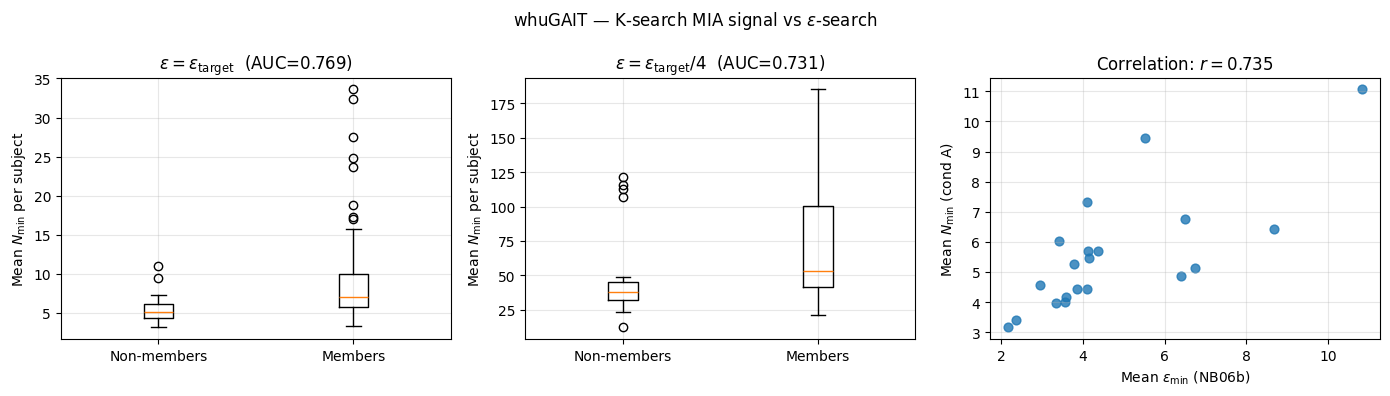

Saved: ../results/whuGAIT/06d_whuGAIT_ksearch_mia.png


In [9]:
# ── Plots ──────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# 1. N_min distribution: member vs non-member (cond A)
ax = axes[0]
subj_nm_A = subject_mean_nmin(n_min_te_A, subj_te)
subj_m_A  = subject_mean_nmin(n_min_tr_A, subj_tr)
ax.boxplot([list(subj_nm_A.values()), list(subj_m_A.values())],
           labels=['Non-members', 'Members'], notch=False)
ax.set_ylabel('Mean $N_{\\min}$ per subject')
ax.set_title(f'$\\varepsilon = \\varepsilon_{{\\mathrm{{target}}}}$  (AUC={auc_A:.3f})')
ax.grid(True, alpha=0.3)

# 2. N_min distribution: member vs non-member (cond B)
ax = axes[1]
subj_nm_B = subject_mean_nmin(n_min_te_B, subj_te)
subj_m_B  = subject_mean_nmin(n_min_tr_B, subj_tr)
ax.boxplot([list(subj_nm_B.values()), list(subj_m_B.values())],
           labels=['Non-members', 'Members'], notch=False)
ax.set_ylabel('Mean $N_{\\min}$ per subject')
ax.set_title(f'$\\varepsilon = \\varepsilon_{{\\mathrm{{target}}}}/16$  (AUC={auc_B:.3f})')
ax.grid(True, alpha=0.3)

# 3. Scatter: eps_min vs N_min for non-member subjects
ax = axes[2]
ax.scatter(eps_vec, nmin_vec, s=40, alpha=0.8)
ax.set_xlabel('Mean $\\varepsilon_{\\min}$ (NB06b)')
ax.set_ylabel('Mean $N_{\\min}$ ($\\varepsilon/16$)')
ax.set_title(f'Correlation: $r = {corr:.3f}$')
ax.grid(True, alpha=0.3)

fig.suptitle(f'{DATASET} — K-search MIA signal vs $\\varepsilon$-search', fontsize=12)
plt.tight_layout()
outpath = RESULT_DIR / f'06d_{DATASET}_ksearch_mia.png'
fig.savefig(outpath, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {outpath}')

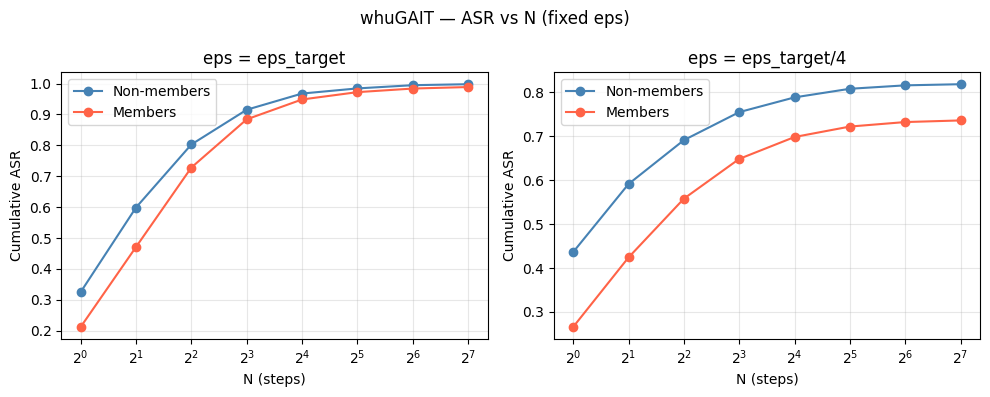

Saved: ../results/whuGAIT/06d_whuGAIT_ksearch_asr_curve.png


In [10]:
# ── ASR curve: fraction of pairs solved as N grows ────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (cond_data, eps_label) in zip(
    axes,
    [({'NN': n_min_te_A, 'MM': n_min_tr_A, 'MN': n_min_mn_A, 'NM': n_min_nm_A}, 'eps_target'),
     ({'NN': n_min_te_B, 'MM': n_min_tr_B, 'MN': n_min_mn_B, 'NM': n_min_nm_B}, 'eps_target/4')],
):
    colors = {'NN': 'steelblue', 'MM': 'tomato', 'MN': 'darkorange', 'NM': 'mediumpurple'}
    styles = {'NN': 'o-', 'MM': 's-', 'MN': '^--', 'NM': 'v--'}
    for label, arr in cond_data.items():
        asr_curve = [(arr <= N).mean() for N in N_GRID]
        ax.plot(N_GRID, asr_curve, styles[label], label=label,
                color=colors[label], linewidth=1.8, markersize=5)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('N (steps)')
    ax.set_ylabel('Cumulative ASR')
    ax.set_title(f'eps = {eps_label}')
    ax.legend()
    ax.grid(True, alpha=0.3)

fig.suptitle(f'{DATASET} — ASR vs N (fixed eps, all pair types)', fontsize=12)
plt.tight_layout()
asr_outpath = RESULT_DIR / f'06d_{DATASET}_ksearch_asr_curve.png'
fig.savefig(asr_outpath, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {asr_outpath}')


In [11]:
# ── LaTeX macros ───────────────────────────────────────────────────────────────
ds = DATASET
prefix = 'whuGAIT' if ds == 'whuGAIT' else ds

def fmt(v, decimals=4):
    return f'{v:.{decimals}f}'

latex_lines = [
    f'% Auto-generated by 06d_k_search_mia.ipynb [{ds}]: DO NOT EDIT MANUALLY',
    '',
    f'\\providecommand{{\\ksMIANminAUCFull{prefix}}}{{}}',
    f'\\renewcommand{{\\ksMIANminAUCFull{prefix}}}{{{fmt(auc_A)}}}',
    f'\\providecommand{{\\ksMIANminEERFull{prefix}}}{{}}',
    f'\\renewcommand{{\\ksMIANminEERFull{prefix}}}{{{fmt(eer_A*100, 2)}\\%}}',
    f'\\providecommand{{\\ksMIANminAUCQuarter{prefix}}}{{}}',
    f'\\renewcommand{{\\ksMIANminAUCQuarter{prefix}}}{{{fmt(auc_B)}}}',
    f'\\providecommand{{\\ksMIANminEERQuarter{prefix}}}{{}}',
    f'\\renewcommand{{\\ksMIANminEERQuarter{prefix}}}{{{fmt(eer_B*100, 2)}\\%}}',
    f'\\providecommand{{\\ksMIAEpsAUCRef{prefix}}}{{}}',
    f'\\renewcommand{{\\ksMIAEpsAUCRef{prefix}}}{{{fmt(auc_eps)}}}',
    f'\\providecommand{{\\ksNminCorrFull{prefix}}}{{}}',
    f'\\renewcommand{{\\ksNminCorrFull{prefix}}}{{{fmt(corr, 3)}}}',
    f'\\providecommand{{\\ksASRTestFull{prefix}}}{{}}',
    f'\\renewcommand{{\\ksASRTestFull{prefix}}}{{{fmt(asr_te_A, 3)}}}',
    f'\\providecommand{{\\ksASRTrainFull{prefix}}}{{}}',
    f'\\renewcommand{{\\ksASRTrainFull{prefix}}}{{{fmt(asr_tr_A, 3)}}}',
    f'\\providecommand{{\\ksASRTestQuarter{prefix}}}{{}}',
    f'\\renewcommand{{\\ksASRTestQuarter{prefix}}}{{{fmt(asr_te_B, 3)}}}',
    f'\\providecommand{{\\ksASRTrainQuarter{prefix}}}{{}}',
    f'\\renewcommand{{\\ksASRTrainQuarter{prefix}}}{{{fmt(asr_tr_B, 3)}}}',
]


# ── Per-N ASR macros for thesis tables ───────────────────────────────────────
for N in [1, 2, 4, 8, 16, 32, 64, 128]:
    n_str = str(N)
    for cond, n_te, n_tr in [('Full', n_min_te_A, n_min_tr_A),
                              ('Quarter', n_min_te_B, n_min_tr_B)]:
        asr_te = float((n_te <= N).mean())
        asr_tr = float((n_tr <= N).mean())
        latex_lines += [
            f'\\providecommand{{\\ksASRTe{cond}N{n_str}{prefix}}}{{}}'  ,
            f'\\renewcommand{{\\ksASRTe{cond}N{n_str}{prefix}}}{{{asr_te:.3f}}}',
            f'\\providecommand{{\\ksASRTr{cond}N{n_str}{prefix}}}{{}}'  ,
            f'\\renewcommand{{\\ksASRTr{cond}N{n_str}{prefix}}}{{{asr_tr:.3f}}}',
        ]

latex_path = LATEX_DIR / 'nb06d_ksearch_metrics.tex'
with open(latex_path, 'w') as f:
    f.write('\n'.join(latex_lines) + '\n')
print(f'LaTeX macros written to {latex_path}')

# Summary
print(f'\n=== Summary [{ds}] ===')
print(f'AUC(N_min, eps_target):    {auc_A:.4f}  EER={eer_A*100:.2f}%')
print(f'AUC(N_min, eps_target/4):  {auc_B:.4f}  EER={eer_B*100:.2f}%')
print(f'AUC(eps_min, NB06b):       {auc_eps:.4f}')
print(f'eps_min vs N_min corr:     r={corr:.4f}')

LaTeX macros written to ../latex/generated/nb06d_ksearch_metrics.tex

=== Summary [whuGAIT] ===
AUC(N_min, eps_target):    0.7694  EER=29.29%
AUC(N_min, eps_target/4):  0.7306  EER=29.80%
AUC(eps_min, NB06b):       0.5791
eps_min vs N_min corr:     r=0.7354
